# Polynomial Linear Regression — Part A (2D)

## 1. Data Generation

We generate a 2D dataset (one feature `x`, one target `y`) from an underlying
polynomial of chosen degree, then add Gaussian noise to simulate real-world data.

**Model:**  y = f(x) + ε,  where  f(x) = Σ a_k · x^k  and  ε ~ N(0, σ²)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# For reproducibility
RNG_SEED = 42

# Plot default
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(RNG_SEED)

## Data Generate

In [34]:
def generate_plo_data(n_samples=100, n_features = 2, degree=2, x_range=(-3,3), noise_std=0.5, coeffs=None, seed=RNG_SEED):
    
    """
    Generate an m-feature polynomial regression dataset.

    y = Σ_k  c_k · Φ_k(X)  +  ε,   ε ~ N(0, σ²)

    where Φ_k are the monomials produced by PolynomialFeatures.
    """
    
    
    rng = np.random.default_rng(seed)
    
    # --- X:(n,m) uniform in a box ---
    X = rng.uniform(x_range[0], x_range[1], size=(n_samples,n_features))
    
    # -- Build the true polynomial basis using sklearn ---
    pf_true = PolynomialFeatures(degree=degree, include_bias=True)
    Phi = pf_true.fit_transform(X) #(n, n_terms)
    
    # ---- Choose coefficients if not provided ---
    if coeffs is None:
        coeffs = rng.uniform(-1,1, size=Phi.shape[1])
    coeffs = np.asarray(coeffs, dtype = float)
    
    assert len(coeffs) == Phi.shape[1]
    
    # --- True polynomial  ---
    y_true = Phi @ coeffs
    
    # ---- Add noise to the target values ---
    noise = rng.normal(0.0, noise_std, size=n_samples)
    y = y_true + noise
    
    return X, y, y_true, coeffs, pf_true

In [36]:
# --- config for this run ----
N_SAMPLES = 200
N_DIM = 1 # 2D data
NOISE_STD = 1.5
DEGREE = 3
X_RANGE = (-3,3)
COEFFS = [0.5, -1.5, 0.8, 0.3]  # [a0, a1, a2, a3]  -> 3rd-degree polynomial
# --- generate data ---
X, y, y_true, coeffs,_  = generate_plo_data(n_samples=N_SAMPLES, n_features = N_DIM, degree=DEGREE, x_range=X_RANGE, noise_std=NOISE_STD, coeffs=COEFFS)

print("X shape : ", X.shape)
print("y shape : ", y.shape)
print("coeffs : ", coeffs)
print(f"y range : [{y.min():.2f}, {y.max():.2f}]")


X shape :  (200, 1)
y shape :  (200,)
coeffs :  [ 0.5 -1.5  0.8  0.3]
y range : [-2.68, 12.05]


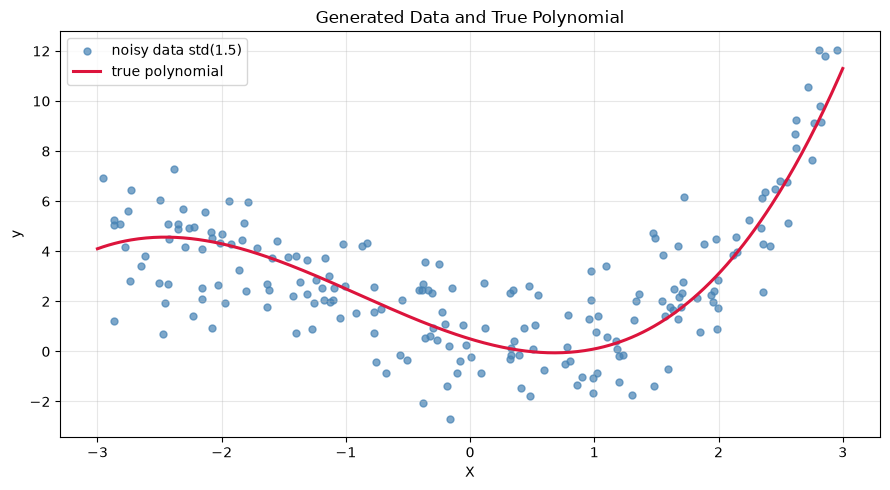

In [37]:
# sort x for smooth true curve line
order = np.argsort(X)
Xs = X[order]

fig, ax = plt.subplots(figsize=(9,5))

# Noisy observations

ax.scatter(X, y, s=25, alpha=0.7, color='steelblue', label=f'noisy data std({NOISE_STD})')

# True underlying polynomial
xx  = np.linspace(X_RANGE[0], X_RANGE[1], 400)
yy_true = np.polyval(coeffs[::-1], xx)
ax.plot(xx, yy_true, color='crimson',lw=2.2, label=f'true polynomial')

ax.set_title("Generated Data and True Polynomial")
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.legend(loc='best')

plt.tight_layout()
plt.show()



In [ ]:
# Save so later sections (model fitting, bias-variance, etc.) can reuse it
np.savez("poly_data_2d.npz", X=X, y=y, y_true=y_true, coeffs=coeffs)
print("Saved -> poly_data_2d.npz")

data = np.load("poly_data_2d.npz")
X, y, y_true, coeffs = data["X"], data["y"], data["y_true"], data["coeffs"]



## 2. Train a Polynomial Linear Regression Model

Pipeline: **PolynomialFeatures(degree=d) → LinearRegression**

We split into train/test, fit, predict, then evaluate with the standard
regression metrics and a set of diagnostic plots.

> Note: this is still *linear regression* in the model parameters — we just
> expand `x` into `[1, x, x², …, x^d]` so the model can fit curves.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score, mean_absolute_percentage_error
)

# X currently has shape (n,). sklearn wants (n,1)
X_col = X.reshape(-1, 1)
print("X_col shape :",X_col.shape)

X_col shape : (200, 1)


In [7]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X_col, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, shuffle=True
)

print(f"Train shape : {X_train.shape[0]} | Test shape : {X_test.shape[0]}")

Train shape : 160 | Test shape : 40


## Build & fir the pipeline


In [40]:
POLY_DEGREE = 3

model = make_pipeline(
    PolynomialFeatures(degree=POLY_DEGREE, include_bias=False), # Transform the input features into polynomial features. x -> [x, x2, x3]
    LinearRegression() # Fit a linear regression model to the (fit a straight line in 3D)

)

model.fit(X_train, y_train)

"""""
# --- Way 2: manual feature expansion + plain LinearRegression ---
X_train_exp = np.column_stack([X_train.ravel(),
                                X_train.ravel()**2,
                                X_train.ravel()**3])
lin_manual = LinearRegression().fit(X_train_exp, y_train)
"""

# Fitted coefficients for the model
lin = model.named_steps['linearregression']
poly = model.named_steps['polynomialfeatures']

y_pred = model.predict(X_test)
print(f"R²  : {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")


print(f"Intercept : {lin.intercept_:.4f}")
print("coefficients (by features) : ")

for name, coef in zip(poly.get_feature_names_out(['x']), lin.coef_):
    print(f" {name:>6s} : {coef:+.4f}")

R²  : 0.6285
RMSE: 1.5134
Intercept : 0.4396
coefficients (by features) : 
      x : -1.2895
    x^2 : +0.7951
    x^3 : +0.2921


In [41]:
# Prediction on test set
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Dense grid for smooth curves
x_grid = np.linspace(X_RANGE[0], X_RANGE[1], 500).reshape(-1, 1)
y_grid_pred = model.predict(x_grid)


In [42]:
# All Metric Evaluation 

def regression_metrics(y_true, y_pred, n_features, name=""):
    
    n=len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    ev = explained_variance_score(y_true, y_pred)
    
    # Adjusted R2 : penalises extra features
    adj_r2 = 1 - (1 - r2)*(n - 1)/(n - n_features-1)
    
    # MAPE - guard against zeros in y_true
    if np.all(np.abs(y_true) > 1e-8):
        mape = mean_absolute_percentage_error(y_true, y_pred)*100
        mape_str = f"{mape:2f}%"
    else:
        mape_str = 'n/a (y contains ~0)'
    
    # Max absolute error
    max_err = np.max(np.abs(y_true - y_pred))
    
    return {
        "set": name,
        "n": n,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2,
        "Adj R²": adj_r2,
        "Explained Var": ev,
        "Max |err|": max_err,
        "MAPE": mape_str,
    }

metrics_train = regression_metrics(y_train, y_train_pred, POLY_DEGREE, "train")
metrics_test  = regression_metrics(y_test,  y_test_pred,  POLY_DEGREE, "test")


# Pretty print
def show_metrics(m):
    print(f"--- {m['set'].upper()} (n={m['n']}) ---")
    print(f"  MSE           : {m['MSE']:.4f}")
    print(f"  RMSE          : {m['RMSE']:.4f}")
    print(f"  MAE           : {m['MAE']:.4f}")
    print(f"  R²            : {m['R²']:.4f}")
    print(f"  Adjusted R²   : {m['Adj R²']:.4f}")
    print(f"  Explained Var : {m['Explained Var']:.4f}")
    print(f"  Max |error|   : {m['Max |err|']:.4f}")
    print(f"  MAPE          : {m['MAPE']}")
    print()

show_metrics(metrics_train)
show_metrics(metrics_test)

--- TRAIN (n=160) ---
  MSE           : 2.2342
  RMSE          : 1.4947
  MAE           : 1.1991
  R²            : 0.7093
  Adjusted R²   : 0.7038
  Explained Var : 0.7093
  Max |error|   : 4.1102
  MAPE          : 84.790592%

--- TEST (n=40) ---
  MSE           : 2.2905
  RMSE          : 1.5134
  MAE           : 1.1946
  R²            : 0.6285
  Adjusted R²   : 0.5976
  Explained Var : 0.6727
  Max |error|   : 3.5629
  MAPE          : 66.453851%



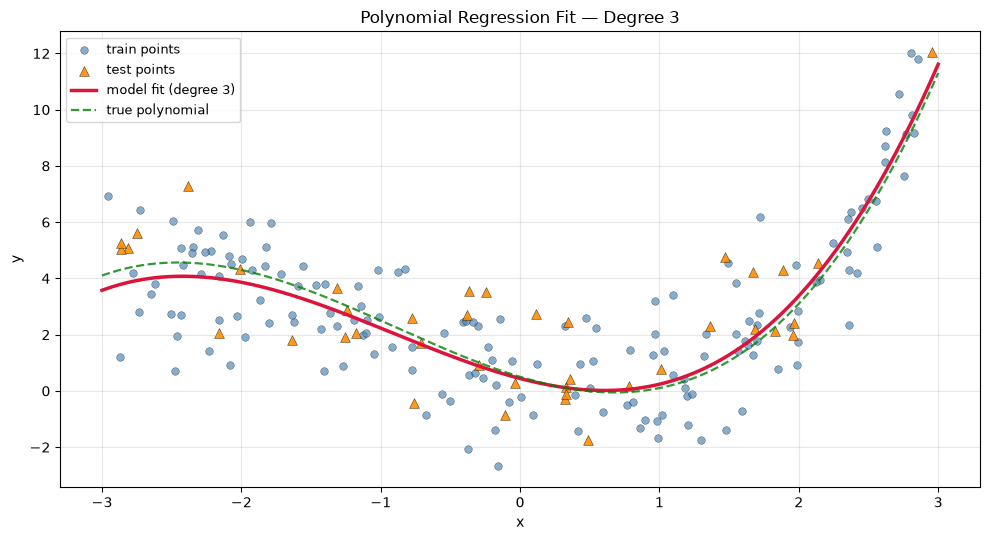

In [18]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Data points
ax.scatter(X_train, y_train, s=30, alpha=0.65, color="steelblue",
           label="train points", edgecolor="k", linewidth=0.3)
ax.scatter(X_test, y_test, s=50, alpha=0.9, color="darkorange",
           marker="^", label="test points", edgecolor="k", linewidth=0.3)

# Model fit
ax.plot(x_grid, y_grid_pred, color="crimson", lw=2.5,
        label=f"model fit (degree {POLY_DEGREE})")

# Ground truth
ax.plot(x_grid, np.polyval(coeffs[::-1], x_grid),
        color="green", lw=1.6, ls="--", alpha=0.8,
        label="true polynomial")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Polynomial Regression Fit — Degree {POLY_DEGREE}")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

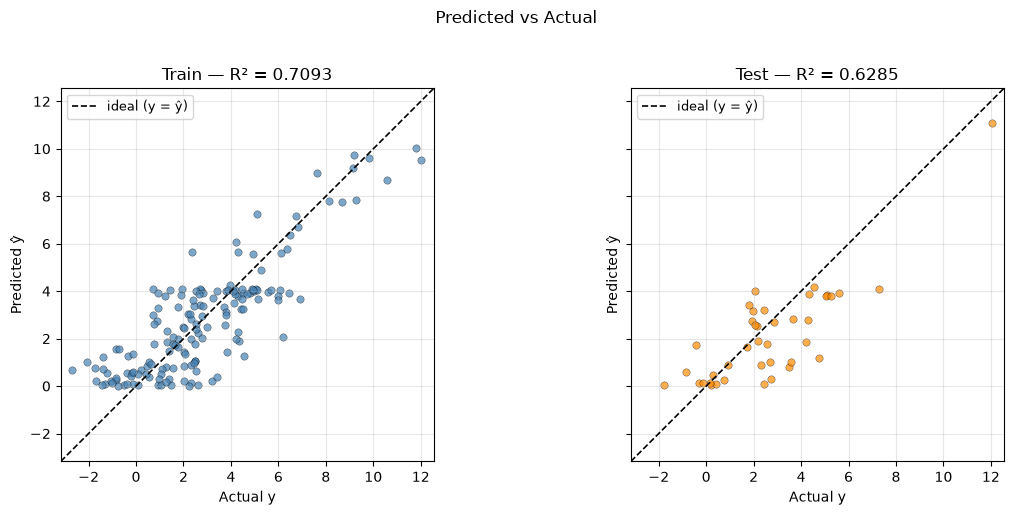

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

lims = [min(y.min(), y_test_pred.min(), y_train_pred.min()) - 0.5,
        max(y.max(), y_test_pred.max(), y_train_pred.max()) + 0.5]

for ax, y_t, y_p, name, color, r2 in [
    (axes[0], y_train, y_train_pred, "Train", "steelblue", metrics_train["R²"]),
    (axes[1], y_test,  y_test_pred,  "Test",  "darkorange", metrics_test["R²"]),
]:
    ax.scatter(y_t, y_p, s=28, alpha=0.7, color=color, edgecolor="k", linewidth=0.3)
    ax.plot(lims, lims, "k--", lw=1.2, label="ideal (y = ŷ)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Actual y")
    ax.set_ylabel("Predicted ŷ")
    ax.set_title(f"{name} — R² = {r2:.4f}")
    ax.legend(loc="upper left", fontsize=9)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Predicted vs Actual", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

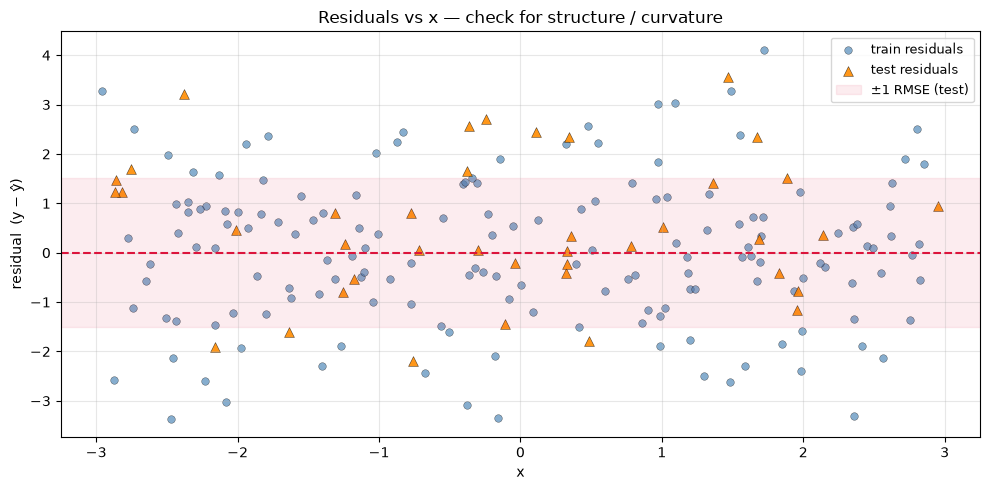

In [20]:
res_train = y_train - y_train_pred
res_test  = y_test  - y_test_pred

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(X_train, res_train, s=30, alpha=0.65, color="steelblue",
           label="train residuals", edgecolor="k", linewidth=0.3)
ax.scatter(X_test,  res_test,  s=50, alpha=0.9,  color="darkorange",
           marker="^", label="test residuals", edgecolor="k", linewidth=0.3)

ax.axhline(0, color="crimson", lw=1.5, ls="--")

# ± 1 RMSE band (test)
ax.axhspan(-metrics_test["RMSE"], metrics_test["RMSE"],
           color="crimson", alpha=0.08, label="±1 RMSE (test)")

ax.set_xlabel("x")
ax.set_ylabel("residual  (y − ŷ)")
ax.set_title("Residuals vs x — check for structure / curvature")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

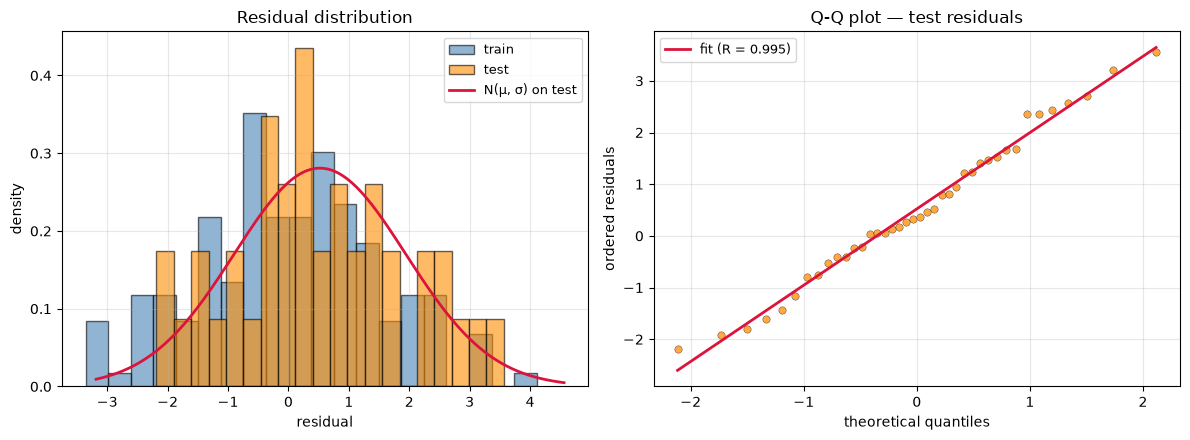

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Histogram + KDE-ish smooth curve ---
ax = axes[0]
ax.hist(res_train, bins=20, alpha=0.6, color="steelblue",
        edgecolor="k", label="train", density=True)
ax.hist(res_test, bins=20, alpha=0.6, color="darkorange",
        edgecolor="k", label="test", density=True)

# overlay normal pdf with test residual stats
from scipy.stats import norm
xs = np.linspace(res_test.min() - 1, res_test.max() + 1, 200)
ax.plot(xs, norm.pdf(xs, res_test.mean(), res_test.std()),
        color="crimson", lw=2, label="N(μ, σ) on test")
ax.set_xlabel("residual")
ax.set_ylabel("density")
ax.set_title("Residual distribution")
ax.legend(fontsize=9)

# --- Q-Q plot for test residuals ---
ax = axes[1]
from scipy.stats import probplot
(osm, osr), (slope, intercept, r) = probplot(res_test, dist="norm")
ax.scatter(osm, osr, s=28, alpha=0.75, color="darkorange",
           edgecolor="k", linewidth=0.3)
ax.plot(osm, slope * osm + intercept, "crimson", lw=2,
        label=f"fit (R = {r:.3f})")
ax.set_xlabel("theoretical quantiles")
ax.set_ylabel("ordered residuals")
ax.set_title("Q-Q plot — test residuals")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

summary = pd.DataFrame([metrics_train, metrics_test]).set_index("set")
summary = summary[["n", "MSE", "RMSE", "MAE", "R²", "Adj R²",
                   "Explained Var", "Max |err|", "MAPE"]]
summary.style.format({
    "n": "{:.0f}",
    "MSE": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}",
    "R²": "{:.4f}",
    "Adj R²": "{:.4f}",
    "Explained Var": "{:.4f}",
    "Max |err|": "{:.4f}",
}).background_gradient(subset=["R²", "Adj R²"], cmap="Greens")

,n,MSE,RMSE,MAE,R²,Adj R²,Explained Var,Max |err|,MAPE
set,,,,,,,,,
train,160,2.2342,1.4947,1.1991,0.7093,0.7038,0.7093,4.1102,84.790592%
test,40,2.2905,1.5134,1.1946,0.6285,0.5976,0.6727,3.5629,66.453851%


### Metric cheat-sheet
| Metric | Lower is better? | Notes |
|---|---|---|
| MSE | ✅ | squashes large errors — sensitive to outliers |
| RMSE | ✅ | same units as y — easiest to interpret |
| MAE | ✅ | robust-ish; in units of y |
| R² | ❌ (1 is perfect) | fraction of variance explained |
| Adj R² | ❌ (1 is perfect) | penalises useless extra features |
| Explained Var | ❌ (1 is perfect) | near-identical to R² for unbiased fits |
| Max abs err | ✅ | worst-case error |
| MAPE | ✅ | %; unreliable when y ≈ 0 |

### Diagnostic reading
- **Residuals random around 0** → model captures the structure.
- **Curved residuals** → increase `POLY_DEGREE` (underfitting).
- **Huge variance in test R² vs train R²** → overfitting.
- **Funnel-shaped residuals** → heteroscedastic noise (not the model's fault).
- **Q-Q deviates at tails** → errors aren't Gaussian; may affect CIs.